In [56]:
# Notebook 02 — Data Preprocessing

## Objectif
L'objectif de ce notebook est de préparer les données Telco Customer Churn pour l'entraînement des modèles de Machine Learning.

Les étapes :
1. Charger le dataset nettoyé.
2. Séparer les variables explicatives X et la cible y.
3. Supprimer la colonne customerID.
4. Diviser les données en Train et Test.
5. Encoder les variables catégorielles.
6. Standardiser les variables numériques.
7. Sauvegarder les données préparées.

SyntaxError: invalid syntax (4110738686.py, line 4)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

print("Bibliothèques importées avec succès !")

In [ ]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "telco_churn_clean.csv"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier du projet :", PROJECT_ROOT)
print("Chemin du dataset :", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError("Dataset introuvable ! Vérifiez le Notebook 01.")

In [ ]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "telco_churn_clean.csv"

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
MODELS_DIR = PROJECT_ROOT / "models"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier du projet :", PROJECT_ROOT)
print("Chemin du dataset :", DATA_PATH)

if not DATA_PATH.exists():
    raise FileNotFoundError("Dataset introuvable ! Vérifiez le Notebook 01.")

In [57]:
df = pd.read_csv(DATA_PATH)

print("Dimensions du dataset :", df.shape)

display(df.head())

Dimensions du dataset : (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [58]:
print("Informations générales :")
df.info()

print("\nValeurs manquantes :")
print(df.isnull().sum().sum())

print("\nNombre de doublons :")
print(df.duplicated().sum())

Informations générales :
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-n

In [59]:
# Transformer la variable cible
y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Vérifier la cible
print("Distribution de la cible :")
print(y.value_counts())

# Supprimer Churn et customerID des variables explicatives
X = df.drop(columns=["Churn", "customerID"])

print("\nDimensions de X :", X.shape)
print("Dimensions de y :", y.shape)

Distribution de la cible :
Churn
0    5174
1    1869
Name: count, dtype: int64

Dimensions de X : (7043, 19)
Dimensions de y : (7043,)


In [60]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Variables numériques :", len(numeric_features))
print(numeric_features)

print("\nVariables catégorielles :", len(categorical_features))
print(categorical_features)

Variables numériques : 4
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variables catégorielles : 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\Octinz\AppData\Local\Temp\ipykernel_27996\3087476384.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [61]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Variables numériques :", len(numeric_features))
print(numeric_features)

print("\nVariables catégorielles :", len(categorical_features))
print(categorical_features)

Variables numériques : 4
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variables catégorielles : 15
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


C:\Users\Octinz\AppData\Local\Temp\ipykernel_27996\3087476384.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [62]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (5634, 19)
X_test : (1409, 19)
y_train : (5634,)
y_test : (1409,)


In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (5634, 19)
X_test : (1409, 19)
y_train : (5634,)
y_test : (1409,)


In [64]:
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", encoder)
])

print("Pipeline catégoriel créé avec succès !")

Pipeline catégoriel créé avec succès !


In [65]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Traitement des variables numériques
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Traitement des variables catégorielles
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

In [66]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ],
    remainder="drop"
)

print("Preprocessor créé avec succès !")

Preprocessor créé avec succès !


In [67]:
# Apprendre les transformations sur Train
X_train_processed_array = preprocessor.fit_transform(X_train)

# Appliquer les transformations sur Test
X_test_processed_array = preprocessor.transform(X_test)

print("Preprocessing terminé !")

Preprocessing terminé !


In [68]:
feature_names = preprocessor.get_feature_names_out()

X_train_processed = pd.DataFrame(
    X_train_processed_array,
    columns=feature_names,
    index=X_train.index
)

X_test_processed = pd.DataFrame(
    X_test_processed_array,
    columns=feature_names,
    index=X_test.index
)

display(X_train_processed.head())

print("Dimensions Train :", X_train_processed.shape)
print("Dimensions Test :", X_test_processed.shape)

,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,cat__PhoneService_No,cat__PhoneService_Yes,cat__MultipleLines_No,cat__MultipleLines_No phone service,cat__MultipleLines_Yes,cat__InternetService_DSL,cat__InternetService_Fiber optic,cat__InternetService_No,cat__OnlineSecurity_No,cat__OnlineSecurity_No internet service,cat__OnlineSecurity_Yes,cat__OnlineBackup_No,cat__OnlineBackup_No internet service,cat__OnlineBackup_Yes,cat__DeviceProtection_No,cat__DeviceProtection_No internet service,cat__DeviceProtection_Yes,cat__TechSupport_No,cat__TechSupport_No internet service,cat__TechSupport_Yes,cat__StreamingTV_No,cat__StreamingTV_No internet service,cat__StreamingTV_Yes,cat__StreamingMovies_No,cat__StreamingMovies_No internet service,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
3738,-0.441773,0.102371,-0.521976,-0.262257,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3151,-0.441773,-0.711743,0.337478,-0.503635,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4860,-0.441773,-0.793155,-0.809013,-0.749883,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3867,-0.441773,-0.263980,0.284384,-0.172722,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
3810,-0.441773,-1.281624,-0.676279,-0.989374,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


Dimensions Train : (5634, 45)
Dimensions Test : (1409, 45)


In [69]:
print("Valeurs manquantes Train :",
      X_train_processed.isnull().sum().sum())

print("Valeurs manquantes Test :",
      X_test_processed.isnull().sum().sum())

print("Valeurs infinies Train :",
      np.isinf(X_train_processed.to_numpy()).sum())

print("Valeurs infinies Test :",
      np.isinf(X_test_processed.to_numpy()).sum())

print("Nombre de features après encodage :",
      X_train_processed.shape[1])

print("Colonnes identiques Train/Test :",
      X_train_processed.columns.equals(X_test_processed.columns))

Valeurs manquantes Train : 0
Valeurs manquantes Test : 0
Valeurs infinies Train : 0
Valeurs infinies Test : 0
Nombre de features après encodage : 45
Colonnes identiques Train/Test : True


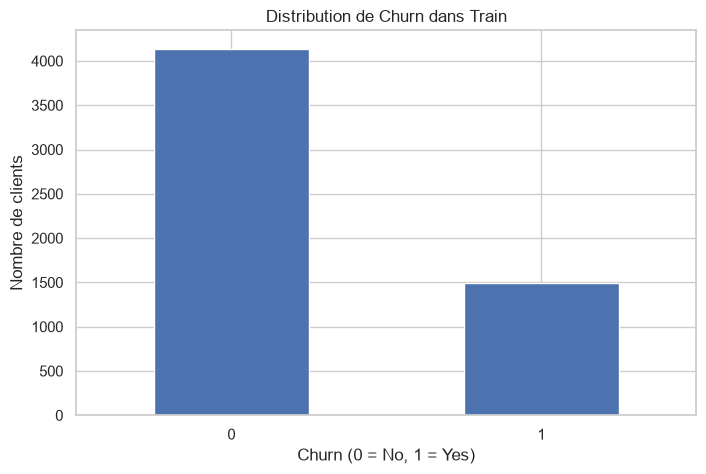

In [70]:
plt.figure(figsize=(8, 5))

y_train.value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Distribution de Churn dans Train")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Nombre de clients")
plt.xticks(rotation=0)

plt.show()

In [71]:
# Sauvegarder les variables explicatives
X_train_processed.to_csv(
    PROCESSED_DIR / "X_train_processed.csv",
    index=False
)

X_test_processed.to_csv(
    PROCESSED_DIR / "X_test_processed.csv",
    index=False
)

# Sauvegarder la cible
y_train.to_frame(name="Churn").to_csv(
    PROCESSED_DIR / "y_train.csv",
    index=False
)

y_test.to_frame(name="Churn").to_csv(
    PROCESSED_DIR / "y_test.csv",
    index=False
)

# Sauvegarder le preprocessor
joblib.dump(
    preprocessor,
    MODELS_DIR / "preprocessor.joblib"
)

print("Tous les fichiers ont été sauvegardés avec succès !")

Tous les fichiers ont été sauvegardés avec succès !


In [72]:
print("Fichiers générés :")

files = [
    PROCESSED_DIR / "X_train_processed.csv",
    PROCESSED_DIR / "X_test_processed.csv",
    PROCESSED_DIR / "y_train.csv",
    PROCESSED_DIR / "y_test.csv",
    MODELS_DIR / "preprocessor.joblib"
]

for file in files:
    print(file.relative_to(PROJECT_ROOT), "->", file.exists())

Fichiers générés :
data\processed\X_train_processed.csv -> True
data\processed\X_test_processed.csv -> True
data\processed\y_train.csv -> True
data\processed\y_test.csv -> True
models\preprocessor.joblib -> True


In [73]:
import pandas as pd
import joblib
import os

# Vérifier les fichiers
files = [
    "data/processed/X_train_processed.csv",
    "data/processed/X_test_processed.csv",
    "data/processed/y_train.csv",
    "data/processed/y_test.csv",
    "models/preprocessor.joblib"
]

for file in files:
    print(file, "->", os.path.exists(file))

# Charger les données
X_train = pd.read_csv(files[0])
X_test = pd.read_csv(files[1])
y_train = pd.read_csv(files[2])
y_test = pd.read_csv(files[3])

print("\nDimensions :")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nValeurs manquantes:")
print("X_train:", X_train.isnull().sum().sum())
print("X_test:", X_test.isnull().sum().sum())

data/processed/X_train_processed.csv -> False
data/processed/X_test_processed.csv -> False
data/processed/y_train.csv -> False
data/processed/y_test.csv -> False
models/preprocessor.joblib -> False


FileNotFoundError: [Errno 2] No such file or directory: 'data/processed/X_train_processed.csv'

In [ ]:
import os

print("Current Working Directory:")
print(os.getcwd())

print("\nContenu du dossier actuel:")
print(os.listdir())

In [ ]:
# Conclusion

Dans ce notebook, nous avons réalisé les étapes de Data Preprocessing :

- Séparation des variables explicatives et de la cible.
- Suppression de l'identifiant customerID.
- Division des données en Train et Test.
- Traitement des variables numériques.
- Encodage des variables catégorielles.
- Standardisation des données numériques.
- Sauvegarde des données préparées et du preprocessor.

Les données sont maintenant prêtes pour la phase suivante :
**Model Training et AutoML.**

In [ ]:
import os

# Retourner au dossier principal du projet
PROJECT_DIR = os.path.dirname(os.getcwd())

print("Project directory:", PROJECT_DIR)
print("\nContenu du projet:")

for item in os.listdir(PROJECT_DIR):
    print(item)

In [74]:
import os

print("DATA:")
for root, dirs, files in os.walk(os.path.join(PROJECT_DIR, "data")):
    print(root, files)

print("\nMODELS:")
for root, dirs, files in os.walk(os.path.join(PROJECT_DIR, "models")):
    print(root, files)

DATA:
C:\Users\Octinz\Documents\automl-mlops-platform\data []
C:\Users\Octinz\Documents\automl-mlops-platform\data\processed ['telco_churn_clean.csv', 'telco_churn_exploration.csv', 'X_test_processed.csv', 'X_train_processed.csv', 'y_test.csv', 'y_train.csv']
C:\Users\Octinz\Documents\automl-mlops-platform\data\raw ['Telco-Customer-Churn.csv']

MODELS:
C:\Users\Octinz\Documents\automl-mlops-platform\models ['preprocessor.joblib']


In [75]:
import os
import pandas as pd
import joblib

DATA_DIR = os.path.join(PROJECT_DIR, "data", "processed")
MODEL_DIR = os.path.join(PROJECT_DIR, "models")

# Charger les données
X_train = pd.read_csv(os.path.join(DATA_DIR, "X_train_processed.csv"))
X_test = pd.read_csv(os.path.join(DATA_DIR, "X_test_processed.csv"))

y_train = pd.read_csv(os.path.join(DATA_DIR, "y_train.csv"))
y_test = pd.read_csv(os.path.join(DATA_DIR, "y_test.csv"))

# Charger le preprocessor
preprocessor = joblib.load(
    os.path.join(MODEL_DIR, "preprocessor.joblib")
)

print("Chargement terminé avec succès !")

Chargement terminé avec succès !


In [76]:
print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

print("\nValeurs manquantes :")
print("X_train :", X_train.isnull().sum().sum())
print("X_test  :", X_test.isnull().sum().sum())

print("\nAperçu des données :")
display(X_train.head())

X_train : (5634, 45)
X_test  : (1409, 45)
y_train : (5634, 1)
y_test  : (1409, 1)

Valeurs manquantes :
X_train : 0
X_test  : 0

Aperçu des données :


,num__SeniorCitizen,num__tenure,num__MonthlyCharges,num__TotalCharges,cat__gender_Female,cat__gender_Male,cat__Partner_No,cat__Partner_Yes,cat__Dependents_No,cat__Dependents_Yes,cat__PhoneService_No,cat__PhoneService_Yes,cat__MultipleLines_No,cat__MultipleLines_No phone service,cat__MultipleLines_Yes,cat__InternetService_DSL,cat__InternetService_Fiber optic,cat__InternetService_No,cat__OnlineSecurity_No,cat__OnlineSecurity_No internet service,cat__OnlineSecurity_Yes,cat__OnlineBackup_No,cat__OnlineBackup_No internet service,cat__OnlineBackup_Yes,cat__DeviceProtection_No,cat__DeviceProtection_No internet service,cat__DeviceProtection_Yes,cat__TechSupport_No,cat__TechSupport_No internet service,cat__TechSupport_Yes,cat__StreamingTV_No,cat__StreamingTV_No internet service,cat__StreamingTV_Yes,cat__StreamingMovies_No,cat__StreamingMovies_No internet service,cat__StreamingMovies_Yes,cat__Contract_Month-to-month,cat__Contract_One year,cat__Contract_Two year,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__PaymentMethod_Bank transfer (automatic),cat__PaymentMethod_Credit card (automatic),cat__PaymentMethod_Electronic check,cat__PaymentMethod_Mailed check
0,-0.441773,0.102371,-0.521976,-0.262257,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,-0.441773,-0.711743,0.337478,-0.503635,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.441773,-0.793155,-0.809013,-0.749883,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0
3,-0.441773,-0.263980,0.284384,-0.172722,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
4,-0.441773,-1.281624,-0.676279,-0.989374,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [77]:
print("Dimensions:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nVérification de cohérence:")
print("Train:", len(X_train) == len(y_train))
print("Test:", len(X_test) == len(y_test))

print("\nValeurs manquantes:")
print("Train:", X_train.isnull().sum().sum())
print("Test:", X_test.isnull().sum().sum())

print("\nTypes des données:")
print(X_train.dtypes.value_counts())

Dimensions:
X_train: (5634, 45)
X_test: (1409, 45)
y_train: (5634, 1)
y_test: (1409, 1)

Vérification de cohérence:
Train: True
Test: True

Valeurs manquantes:
Train: 0
Test: 0

Types des données:
float64    45
Name: count, dtype: int64


In [78]:
print("Distribution de y_train :")
print(y_train.iloc[:, 0].value_counts())

print("\nPourcentage de chaque classe :")
print(y_train.iloc[:, 0].value_counts(normalize=True) * 100)

print("\nDistribution de y_test :")
print(y_test.iloc[:, 0].value_counts())

Distribution de y_train :
Churn
0    4139
1    1495
Name: count, dtype: int64

Pourcentage de chaque classe :
Churn
0    73.464679
1    26.535321
Name: proportion, dtype: float64

Distribution de y_test :
Churn
0    1035
1     374
Name: count, dtype: int64


In [79]:
print("Train Churn Rate:")
print(y_train["Churn"].mean() * 100)

print("\nTest Churn Rate:")
print(y_test["Churn"].mean() * 100)

Train Churn Rate:
26.53532126375577

Test Churn Rate:
26.54364797728886
